# 2.01. Последовательное тестирование

**План занятия**

1. Проблема подглядывания: насколько она опасна.
2. SPRT: классический последовательный тест Вальда.
3. mSPRT: смесь альтернатив и двухвыборочный вариант.
4. Always Valid Inference: always-valid p-value и доверительные последовательности.
5. Group Sequential Testing: alpha-spending функции и расчёт границ.
6. Сравнение подходов на симуляции и выбор метода.

### Библиотеки

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ipywidgets import Dropdown, IntSlider, interact
from scipy.stats import norm

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
ALPHA = 0.05

## Проблема подглядывания

Классические методы проверки гипотез разрабатывались для фиксированного, заранее определённого объёма данных: мы задаём уровень значимости и мощность, рассчитываем выборку и один раз проводим тест. В современной практике данные поступают непрерывно. В клинических исследованиях, онлайн-экспериментах и промышленной диагностике результаты можно смотреть в любой момент, и возникает новая проблема.

Это **проблема подглядывания (peeking problem)**. Если мы проверяем гипотезу на накапливающихся данных много раз и останавливаемся при первом значимом результате, вероятность ложного отклонения нулевой гипотезы растёт. Каждый взгляд — это ещё один шанс увидеть случайное отклонение.

Посмотрим на это на A/A-тесте, где эффекта точно нет.

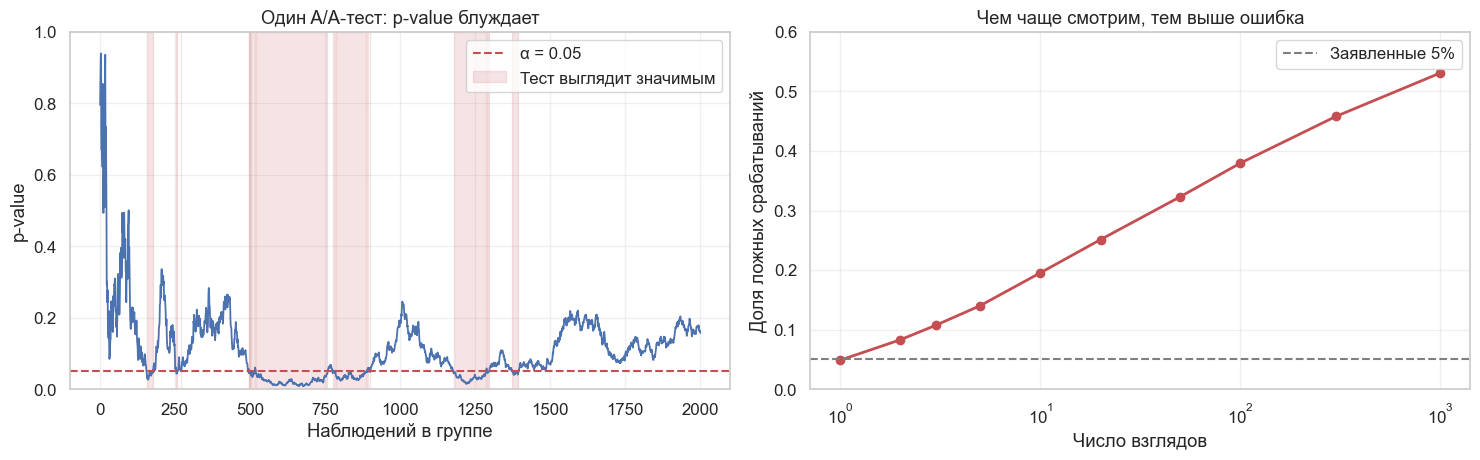

Взглядов,1,2,3,5,10,20,50,100,300,1000
Доля ложных срабатываний,0.049,0.083,0.107,0.14,0.195,0.251,0.323,0.38,0.458,0.531


In [2]:
def peeking_fpr(looks: int, n_sims: int = 20_000, alpha: float = ALPHA, seed: int = 42) -> float:
    """Считает долю A/A-тестов, значимых хотя бы на одном из равномерно расставленных взглядов."""
    rng = np.random.default_rng(seed)
    z = np.cumsum(rng.standard_normal((n_sims, looks), dtype=np.float32), axis=1) / np.sqrt(np.arange(1, looks + 1))
    return float((np.abs(z) > norm.ppf(1 - alpha / 2)).any(axis=1).mean())


def aa_path(n: int = 2000, seed: int = 7) -> tuple:
    """Генерирует один A/A-тест на нормальной метрике и считает p-value после каждого наблюдения."""
    rng = np.random.default_rng(seed)
    difference = rng.standard_normal(n) - rng.standard_normal(n)
    observations = np.arange(1, n + 1)
    z = np.cumsum(difference) / np.sqrt(2 * observations)
    return observations, 2 * norm.sf(np.abs(z))


looks_grid = np.array([1, 2, 3, 5, 10, 20, 50, 100, 300, 1000])
naive_fpr = [peeking_fpr(k) for k in looks_grid]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
observations, pvalues = aa_path()
axes[0].plot(observations, pvalues, color=BLUE, linewidth=1.3)
axes[0].axhline(ALPHA, color=RED, linestyle='--', linewidth=1.5, label='α = 0.05')
axes[0].fill_between(observations, 0, 1, where=pvalues <= ALPHA, color=RED, alpha=0.15, label='Тест выглядит значимым')
axes[0].set(ylim=(0, 1), xlabel='Наблюдений в группе', ylabel='p-value', title='Один A/A-тест: p-value блуждает')
axes[0].legend(loc='upper right')

axes[1].plot(looks_grid, naive_fpr, color=RED, marker='o', linewidth=2)
axes[1].axhline(ALPHA, color=GRAY, linestyle='--', linewidth=1.5, label='Заявленные 5%')
axes[1].set_xscale('log')
axes[1].set(ylim=(0, 0.6), xlabel='Число взглядов', ylabel='Доля ложных срабатываний', title='Чем чаще смотрим, тем выше ошибка')
axes[1].legend()
plt.tight_layout()
plt.show()

pd.DataFrame({'Взглядов': looks_grid, 'Доля ложных срабатываний': np.round(naive_fpr, 3)}).set_index('Взглядов').T

При 10 взглядах доля ложных срабатываний уже около 19.5% вместо заявленных 5%, при 100 взглядах 38%, при 1000 взглядов 53%. При неограниченном числе взглядов обычный тест рано или поздно сработает почти наверняка.

**Попробуйте сами.** Эта ячейка интерактивная: выберите число взглядов и другой A/A-тест. Точки показывают моменты проверки, а заголовок говорит, остановили бы мы тест. Статичная версия показана выше.

In [3]:
def peeking_demo(looks: int = 10, seed: int = 7) -> None:
    """Показывает p-value одного A/A-теста в моменты взглядов."""
    observations, pvalues = aa_path(seed=seed)
    moments = np.linspace(len(observations) / looks, len(observations), looks).astype(int) - 1
    significant = pvalues[moments] <= ALPHA

    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(observations, pvalues, color=GRAY, linewidth=1)
    ax.scatter(observations[moments], pvalues[moments], color=[RED if flag else BLUE for flag in significant], s=45, zorder=3)
    ax.axhline(ALPHA, color=RED, linestyle='--', linewidth=1.5)
    verdict = f'ложный успех на наблюдении {observations[moments][significant.argmax()]}' if significant.any() else 'тест не сработал'
    ax.set(ylim=(0, 1), xlabel='Наблюдений в группе', ylabel='p-value', title=f'{looks} взглядов: {verdict}')
    plt.tight_layout()
    plt.show()


interact(peeking_demo, looks=IntSlider(value=10, min=1, max=100, description='Взглядов'),
         seed=IntSlider(value=7, min=1, max=50, description='Тест'));

Чтобы сохранить корректность
 при многократных проверках, предложены два основных подхода:

1. **Коррекция уровня значимости (alpha spending).** Подход, доминирующий в клинических испытаниях. Проверки проводятся в ограниченном числе моментов, а за каждую платится долей $\alpha$. Распределение этой платы задаёт **alpha-spending функция**, и суммарная ошибка первого рода остаётся в заявленных рамках.

2. **Всегда валидный вывод (anytime-valid inference).** Подход, восходящий к Дарлингу и Роббинсу (1967) и развитый в современных работах (например, Ramdas et al., 2020). Вывод остаётся корректным при адаптивном выборе момента остановки, вплоть до просмотра после каждого наблюдения. Такие методы опираются на супермартингалы и неравенство Вилле.

## Sequential Probability Ratio Test

**Историческое введение**

Во время Второй мировой войны при Колумбийском университете работала Статистическая исследовательская группа (Statistical Research Group, SRG, 1942–1945). В неё входили Аллен Уоллис, Милтон Фридман, Абрахам Вальд, Якоб Вольфовиц и другие выдающиеся учёные. Группа решала прикладные задачи для военных, в частности задачи контроля качества боеприпасов: испытания дороги и разрушительны, поэтому важно проверять как можно меньше изделий.

Уоллис и Фридман заметили, что фиксированный объём испытаний расточителен: часто решение становится ясным задолго до конца, и испытания можно прекратить раньше. В 1943 году они предложили эту задачу Вальду, и он построил **последовательный критерий отношения правдоподобия** (Sequential Probability Ratio Test, SPRT): вместо фиксированного объёма данных решение принимается или откладывается после каждого нового наблюдения.

Результаты были засекречены до конца войны, после чего Вальд опубликовал работу [«Sequential Tests of Statistical Hypotheses»](https://www.jstor.org/stable/2235829) (1945), которая стала классикой.

У нас есть две простые гипотезы о значении метрики:

$$
H_0 : \theta = \theta_0, \qquad H_1 : \theta = \theta_1
$$

Функция правдоподобия показывает, насколько вероятны данные при параметре $\theta$. Логарифм отношения правдоподобий показывает, какая из двух моделей лучше описывает данные:

$$
\Lambda_n = \log \prod_{i=1}^{n} \frac{f(X_i \mid \theta_1)}{f(X_i \mid \theta_0)} = \sum_{i=1}^{n} \log \frac{f(X_i \mid \theta_1)}{f(X_i \mid \theta_0)}
$$

**SPRT** сравнивает $\Lambda_n$ с нижней границей $A$ и верхней границей $B$:

* $\Lambda_n \ge B$: данные лучше объясняются $H_1$, отвергаем $H_0$;
* $\Lambda_n \le A$: данные лучше объясняются $H_0$, принимаем $H_0$;
* $\Lambda_n \in (A, B)$: собираем следующее наблюдение.

Вальд показал, что границы приближённо равны:

$$
A \approx \log\frac{\beta}{1-\alpha}, \qquad B \approx \log\frac{1-\beta}{\alpha}
$$

**Пример для бернуллиевской величины**

Пусть $P(X_i = 1) = \theta$, а $S_n = \sum X_i$. Тогда:

$$
\Lambda_n = S_n \log \frac{\theta_1}{\theta_0} + (n - S_n) \log \frac{1- \theta_1}{1-\theta_0} = S_n \log \frac{\theta_1(1-\theta_0)}{\theta_0(1-\theta_1)} - n \log \frac{1-\theta_0}{1-\theta_1}
$$

Введём обозначения:

$$
\rho^{-1} = \log\frac{\theta_1(1-\theta_0)}{\theta_0 (1-\theta_1)}, \qquad \eta = \log\frac{1-\theta_0}{1-\theta_1}
$$

Тогда условие $A < \Lambda_n < B$ при $\theta_1 > \theta_0$ переписывается как:

$$
\rho A + \rho\eta n < S_n < \rho B + \rho\eta n
$$

То есть границы для числа успехов — параллельные прямые с наклоном $\rho\eta$ и сдвигами $\rho A$ и $\rho B$.

#### Реализация

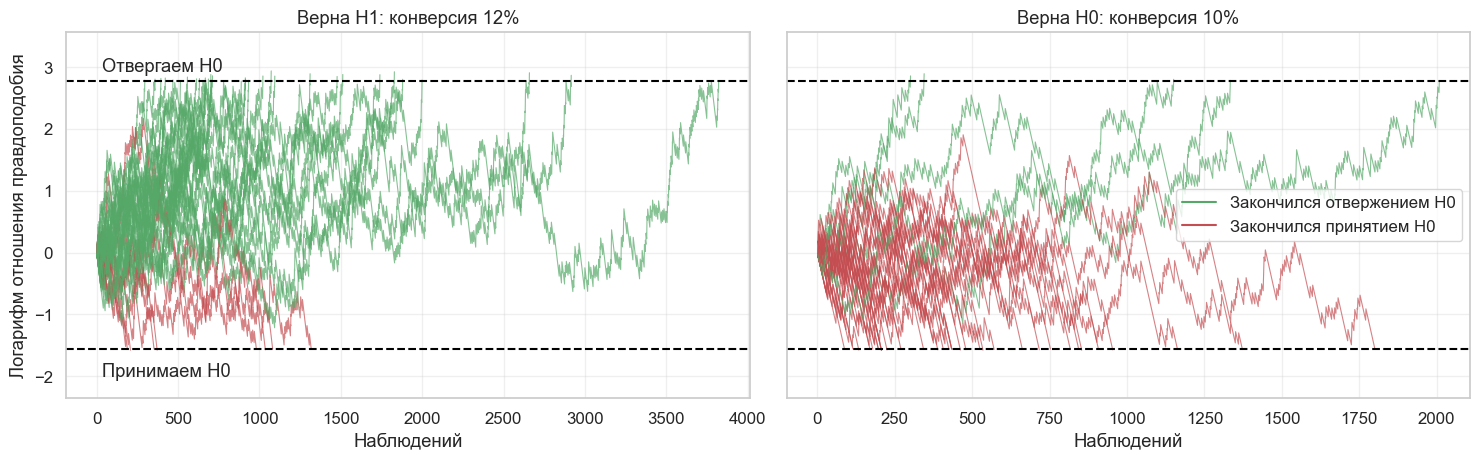

In [4]:
def sprt_bounds(alpha: float, beta: float) -> tuple:
    """Возвращает границы Вальда для логарифма отношения правдоподобия."""
    return np.log(beta / (1 - alpha)), np.log((1 - beta) / alpha)


def sprt_paths(x: np.ndarray, p0: float, p1: float) -> np.ndarray:
    """Считает накопленный логарифм отношения правдоподобия по бинарным наблюдениям."""
    return np.cumsum(x * np.log(p1 / p0) + (1 - x) * np.log((1 - p1) / (1 - p0)), axis=-1)


def sprt_decide(llr: np.ndarray, lower: float, upper: float) -> tuple:
    """Находит для каждого пути шаг и направление первого пересечения границы."""
    crossed = (llr >= upper) | (llr <= lower)
    any_crossed = crossed.any(axis=1)
    first = np.where(any_crossed, crossed.argmax(axis=1), llr.shape[1] - 1)
    rejected = any_crossed & (llr[np.arange(len(llr)), first] >= upper)
    return first + 1, rejected, any_crossed


P0, P1, BETA = 0.10, 0.12, 0.2
lower, upper = sprt_bounds(ALPHA, BETA)
rng = np.random.default_rng(666)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, true_p, title in [(axes[0], P1, 'Верна H1: конверсия 12%'), (axes[1], P0, 'Верна H0: конверсия 10%')]:
    x = (rng.random((40, 4000)) < true_p).astype(np.int8)
    llr = sprt_paths(x, P0, P1)
    stops, rejected, _ = sprt_decide(llr, lower, upper)
    for path, stop, decision in zip(llr, stops, rejected):
        ax.plot(np.arange(1, stop + 1), path[:stop], color=GREEN if decision else RED, linewidth=0.8, alpha=0.7)
    ax.axhline(upper, color='black', linestyle='--', linewidth=1.5)
    ax.axhline(lower, color='black', linestyle='--', linewidth=1.5)
    ax.set(xlabel='Наблюдений', title=title)
axes[0].set_ylabel('Логарифм отношения правдоподобия')
axes[0].text(30, upper + 0.15, 'Отвергаем H0')
axes[0].text(30, lower - 0.45, 'Принимаем H0')
axes[0].set_ylim(lower - 0.8, upper + 0.8)
axes[1].plot([], [], color=GREEN, label='Закончился отвержением H0')
axes[1].plot([], [], color=RED, label='Закончился принятием H0')
axes[1].legend(loc='center right')
plt.tight_layout()
plt.show()

Проверим свойства теста на симуляции и сравним с классическим односторонним тестом той же точности.

In [5]:
def sprt_properties(true_p: float, n_sims: int = 3000, max_n: int = 20_000, seed: int = 1) -> tuple:
    """Оценивает долю отклонений H0 и средний размер выборки SPRT."""
    rng = np.random.default_rng(seed)
    llr = sprt_paths((rng.random((n_sims, max_n), dtype=np.float32) < true_p).astype(np.int8), P0, P1)
    stops, rejected, finished = sprt_decide(llr, lower, upper)
    return rejected.mean(), stops.mean(), finished.mean()


z_a, z_b = norm.ppf(1 - ALPHA), norm.ppf(1 - BETA)
fixed_n = ((z_a * np.sqrt(P0 * (1 - P0)) + z_b * np.sqrt(P1 * (1 - P1))) / (P1 - P0)) ** 2

rows = {}
for name, true_p in [('Верна H0 (10%)', P0), ('Верна H1 (12%)', P1), ('Эффект вдвое больше (14%)', 0.14)]:
    share, mean_n, finished = sprt_properties(true_p)
    rows[name] = {'Доля отклонений H0': round(share, 3), 'Средний размер': round(mean_n), 'Закончилось': round(finished, 3)}

print(f'Фиксированный размер выборки для α = 5%, β = 20%: {fixed_n:.0f}')
pd.DataFrame(rows).T

Фиксированный размер выборки для α = 5%, β = 20%: 1471


,Доля отклонений H0,Средний размер,Закончилось
Верна H0 (10%),0.047,680.0,1.0
Верна H1 (12%),0.800,929.0,1.0
Эффект вдвое больше (14%),0.988,447.0,1.0


Тест держит заявленные ошибки: ложных срабатываний 4.7%, мощность 80%. Выигрыш заметный: в среднем 680 наблюдений при верной $H_0$ и 929 при верной $H_1$ против 1471 у фиксированного теста, то есть экономия 37–54%. Но это среднее: отдельный тест может идти намного дольше фиксированного.

У этого подхода есть три проблемы, которые мешают использовать его в A/B-тестах:

1. **Одна выборка.** Простой SPRT сравнивает данные с известным значением $\theta_0$, а в A/B-тесте базовая конверсия неизвестна, и нужно сравнивать две группы.
2. **Простая альтернатива.** Тест требует фиксированного значения $\theta_1$, хотя реальный эффект заранее неизвестен.
3. **Неограниченность.** Статистика с вероятностью 1 пересекает одну из границ, но это может занять очень много времени, а заранее ограниченной длительности у теста нет.

Последующие методы призваны решить эти проблемы.

## Mixture Sequential Probability Ratio Test

mSPRT решает проблему фиксированной альтернативы. Вместо одного значения $\theta_1$ мы проверяем $H_0: \theta = \theta_0$ против $H_1: \theta \neq \theta_0$ и усредняем отношение правдоподобия по всем возможным значениям с плотностью $h(\theta)$. Вместо вопроса «насколько вероятны данные при конкретном $\theta_1$ по сравнению с $\theta_0$?» мы спрашиваем: «какова средняя вероятность данных по всему пространству альтернатив?»

$$
\Lambda_n^h = \int_{\Theta} \prod_{i=1}^{n} \frac{f(X_i \mid \theta)}{f(X_i \mid \theta_0)}\, h(\theta)\, d\theta
$$

Здесь $h(\theta)$ — смешивающая плотность, положительная всюду. Она не означает, что мы верим в это распределение, а просто задаёт вес альтернатив.

**Отличие от SPRT.** При верной $H_0$ процесс $\Lambda_n^h$ является мартингалом со средним 1, и работает только **одна граница**: отвергаем $H_0$, когда $\Lambda_n^h \ge 1/\alpha$. Граница для принятия $H_0$ здесь не используется: для сложной альтернативы нет значения $\theta_1$, для которого можно обещать мощность. Тест либо находит эффект, либо идёт до ограничения по выборке.

**Двухвыборочный вариант.** Johari et al. (2015) применили mSPRT к A/B-тестам. Пусть группы имеют по $n$ наблюдений с дисперсией $\sigma^2$, а $\bar\Delta_n$ — разность средних. Для нормальной смеси $\theta \sim N(0, \tau^2)$ интеграл считается аналитически:

$$
\Lambda_n = \sqrt{\frac{2\sigma^2}{2\sigma^2 + n\tau^2}}\ \exp\left(\frac{n^2 \tau^2 \bar\Delta_n^2}{4\sigma^2 (2\sigma^2 + n\tau^2)}\right)
$$

Для конверсий нормальность работает приближённо, а $\sigma^2$ заменяется оценкой, поэтому контроль ошибки здесь асимптотический. Параметр $\tau$ выбирают близким к ожидаемому эффекту.

#### Реализация

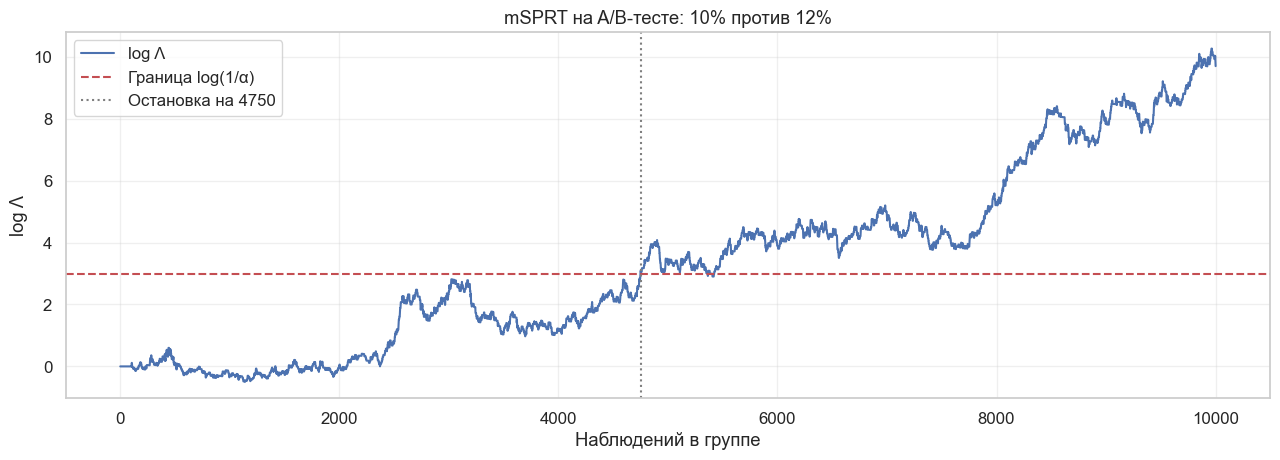

In [6]:
def msprt_log_lambda(mean_diff: np.ndarray, n: np.ndarray, sigma2: np.ndarray, tau: float) -> np.ndarray:
    """Считает логарифм смешанного отношения правдоподобия из работы Johari et al."""
    v = 2 * sigma2
    return 0.5 * np.log(v / (v + n * tau ** 2)) + n ** 2 * tau ** 2 * mean_diff ** 2 / (2 * v * (v + n * tau ** 2))


def generate_ab_data(conversion_a: float, conversion_b: float, sample_size: int, seed: int = None) -> tuple:
    """Генерирует бинарные наблюдения групп A и B."""
    rng = np.random.default_rng(seed)
    return (rng.random(sample_size) < conversion_a).astype(int), (rng.random(sample_size) < conversion_b).astype(int)


def run_msprt(data_a: np.ndarray, data_b: np.ndarray, tau: float, alpha: float = ALPHA, burn_in: int = 100) -> dict:
    """Запускает mSPRT на потоке пар наблюдений, дисперсия оценивается по накопленным данным."""
    n = np.arange(1, len(data_a) + 1)
    mean_a, mean_b = np.cumsum(data_a) / n, np.cumsum(data_b) / n
    pooled = (mean_a + mean_b) / 2
    sigma2 = np.clip(pooled * (1 - pooled), 1e-6, None)
    log_lambda = msprt_log_lambda(mean_b - mean_a, n, sigma2, tau)
    log_lambda[:burn_in] = 0.0  # на первых наблюдениях оценка дисперсии ненадёжна

    crossed = np.nonzero(log_lambda >= np.log(1 / alpha))[0]
    return {'n': n, 'log_lambda': log_lambda, 'difference': mean_b - mean_a, 'sigma2': sigma2,
            'stop': int(crossed[0]) + 1 if len(crossed) else None}


CONVERSION_A, CONVERSION_B = 0.10, 0.12
data_a, data_b = generate_ab_data(CONVERSION_A, CONVERSION_B, 10_000, seed=666)
tau = 0.02
msprt_result = run_msprt(data_a, data_b, tau)

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(msprt_result['n'], msprt_result['log_lambda'], color=BLUE, linewidth=1.5, label='log Λ')
ax.axhline(np.log(1 / ALPHA), color=RED, linestyle='--', linewidth=1.5, label='Граница log(1/α)')
if msprt_result['stop']:
    ax.axvline(msprt_result['stop'], color=GRAY, linestyle=':', linewidth=1.5, label=f"Остановка на {msprt_result['stop']}")
ax.set(xlabel='Наблюдений в группе', ylabel='log Λ', title='mSPRT на A/B-тесте: 10% против 12%')
ax.legend()
plt.tight_layout()
plt.show()

## Always Valid Inference

Always-Valid Inference — подход, в котором p-value и доверительные интервалы остаются корректными на протяжении всего сбора данных, а не только в фиксированный момент.

**1. Always-valid p-значения**

Классическое p-значение контролирует ошибку только в заранее выбранный момент. Always-valid p-значение — это последовательность $(p_t)$, для которой при любом уровне $\alpha$ и **любом моменте остановки** $T$ выполняется:

$$
P_{H_0}(p_T \le \alpha) \le \alpha
$$

Это сильнее поточечного условия $P_{H_0}(p_t \le \alpha) \le \alpha$ для фиксированного $t$.

**Построение через супермартингалы.** **E-значение** — это неотрицательная величина $E$ с $\mathbb{E}_{H_0}[E] \le 1$. Если $(M_t)$ — неотрицательный супермартингал с $M_0 = 1$, то по **неравенству Вилле**:

$$
P_{H_0}\left( \sup_{t \ge 0} M_t \ge \frac{1}{\alpha} \right) \le \alpha
$$

Тогда $p_t = \min\left(1, 1 / \sup_{s \le t} M_s\right)$ будет always-valid p-значением. Для mSPRT роль $M_t$ играет $\Lambda_t$: при $H_0$ это мартингал, поэтому $p_0 = 1$, $p_n = \min(p_{n-1}, 1 / \Lambda_n)$.

**2. Доверительные последовательности (Confidence Sequences)**

Классический интервал покрывает параметр с вероятностью $1-\alpha$ при заранее заданном $n$. Доверительная последовательность покрывает его **одновременно для всех** моментов времени:

$$
P\left( \forall t \ge 1: \psi \in C_t \right) \ge 1 - \alpha
$$

Такую последовательность получают обращением always-valid теста: в $C_t$ попадают все значения $\psi_0$, для которых тест $H_0: \psi = \psi_0$ ещё не сработал. Для mSPRT из условия $\Lambda_n(\psi) < 1/\alpha$ получаем полуширину интервала:

$$
r_n = \sqrt{\frac{2 v (v + n\tau^2)}{n^2 \tau^2} \left( \log\frac{1}{\alpha} + \frac{1}{2} \log\frac{v + n\tau^2}{v} \right)}, \qquad v = 2\sigma^2
$$

**3. Последовательные тесты и e-процессы**

Правило остановки формулируется просто: остановиться и отвергнуть $H_0$ в первый момент, когда e-процесс $E_t$ достиг $1/\alpha$. По неравенству Вилле вероятность ложного срабатывания не превышает $\alpha$.

**Хёффдинг: строгая гарантия без нормальности**

Пусть $D_i = B_i - A_i \in [-1, 1]$ — разность наблюдений, а $S_t = \sum_{i \le t}(D_i - \Delta)$. Неравенство Хёффдинга для ограниченной величины даёт, что

$$
M_t(\lambda) = \exp\left(\lambda S_t - \frac{t\lambda^2 c^2}{8}\right), \qquad c = 2
$$

является супермартингалом при любом $\lambda$. Выбор $\lambda$ убирается смесью $\lambda \sim N(0, 1/\rho)$, что снова даёт супермартингал:

$$
M_t = \sqrt{\frac{\rho}{t + \rho}}\ \exp\left(\frac{S_t^2}{2(t + \rho)}\right)
$$

Условие $M_t < 1/\alpha$ даёт доверительную последовательность для $\Delta$:

$$
\left|\overline{D}_t - \Delta\right| \le \frac{1}{t}\sqrt{(t + \rho) \log\frac{t + \rho}{\rho\,\alpha^2}}
$$

Здесь нет никаких приближений: граница верна на любых выборках. Цена — ширина: она рассчитана на самую большую возможную дисперсию.

**Важная ловушка.** Нельзя взять обычное неравенство Хёффдинга для фиксированного $t$, $P(|S_t| \ge s) \le 2\exp(-s^2 / (2t))$, и просто накапливать минимум таких p-значений. Граница для фиксированного $t$ растёт как $\sqrt{t}$, а по закону повторного логарифма блуждание выходит за неё снова и снова. Поэтому такая конструкция не always-valid. Проверим на случайных блужданиях с $D_i = \pm 1$, для которых граница Хёффдинга самая точная.

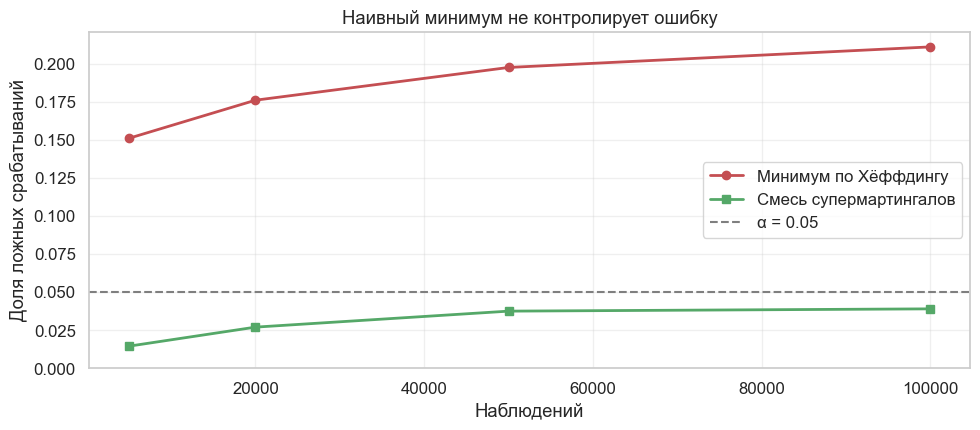

,Минимум по Хёффдингу,Смесь супермартингалов
Наблюдений,,
5000,0.151,0.014
20000,0.176,0.027
50000,0.198,0.038
100000,0.211,0.039


In [7]:
def hoeffding_radius(t: np.ndarray, alpha: float = ALPHA, rho: float = 1000.0) -> np.ndarray:
    """Считает полуширину доверительной последовательности на смеси супермартингалов Хёффдинга."""
    return np.sqrt((t + rho) * np.log((t + rho) / (rho * alpha ** 2))) / t


def msprt_radius(n: np.ndarray, sigma2: np.ndarray, tau: float, alpha: float = ALPHA) -> np.ndarray:
    """Считает полуширину доверительной последовательности, полученной обращением mSPRT."""
    v = 2 * sigma2
    return np.sqrt(2 * v * (v + n * tau ** 2) / (n ** 2 * tau ** 2) * (np.log(1 / alpha) + 0.5 * np.log((v + n * tau ** 2) / v)))


def walk_crossing(horizons: np.ndarray, n_sims: int = 2000, chunk: int = 5000, seed: int = 3) -> pd.DataFrame:
    """Считает долю блужданий ±1, пересёкших границы, до каждого горизонта."""
    rng = np.random.default_rng(seed)
    threshold = np.log(2 / ALPHA)
    sums = np.zeros(n_sims)
    crossed_naive = np.zeros(n_sims, dtype=bool)
    crossed_mixture = np.zeros(n_sims, dtype=bool)
    rows, position = [], 0
    for horizon in horizons:
        while position < horizon:
            steps = 2 * rng.integers(0, 2, size=(n_sims, chunk), dtype=np.int8).astype(np.int32) - 1
            path = sums[:, None] + np.cumsum(steps, axis=1)
            t = np.arange(position + 1, position + chunk + 1)
            crossed_naive |= (path ** 2 / (2 * t) >= threshold).any(axis=1)
            crossed_mixture |= (np.abs(path) / t >= hoeffding_radius(t)).any(axis=1)
            sums = path[:, -1]
            position += chunk
        rows.append({'Наблюдений': horizon, 'Минимум по Хёффдингу': crossed_naive.mean(), 'Смесь супермартингалов': crossed_mixture.mean()})
    return pd.DataFrame(rows).set_index('Наблюдений')


walk_results = walk_crossing(np.array([5_000, 20_000, 50_000, 100_000]))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(walk_results.index, walk_results['Минимум по Хёффдингу'], color=RED, marker='o', linewidth=2, label='Минимум по Хёффдингу')
ax.plot(walk_results.index, walk_results['Смесь супермартингалов'], color=GREEN, marker='s', linewidth=2, label='Смесь супермартингалов')
ax.axhline(ALPHA, color=GRAY, linestyle='--', linewidth=1.5, label='α = 0.05')
ax.set(ylim=(0, None), xlabel='Наблюдений', ylabel='Доля ложных срабатываний', title='Наивный минимум не контролирует ошибку')
ax.legend()
plt.tight_layout()
plt.show()

walk_results.round(3)

Наивный минимум уже к 5 000 наблюдений даёт 15% ложных срабатываний, к 100 000 наблюдений 21%, и эта доля продолжает расти. Смесь супермартингалов остаётся ниже 5% на всём пути.

#### Реализация

Построим обе доверительные последовательности для примера с конверсиями 10% и 12% и сравним их с обычным интервалом, рассчитанным для фиксированного $n$. Затем проверим покрытие: как часто за весь A/A-тест интервал хоть раз не накрывает истинное значение.

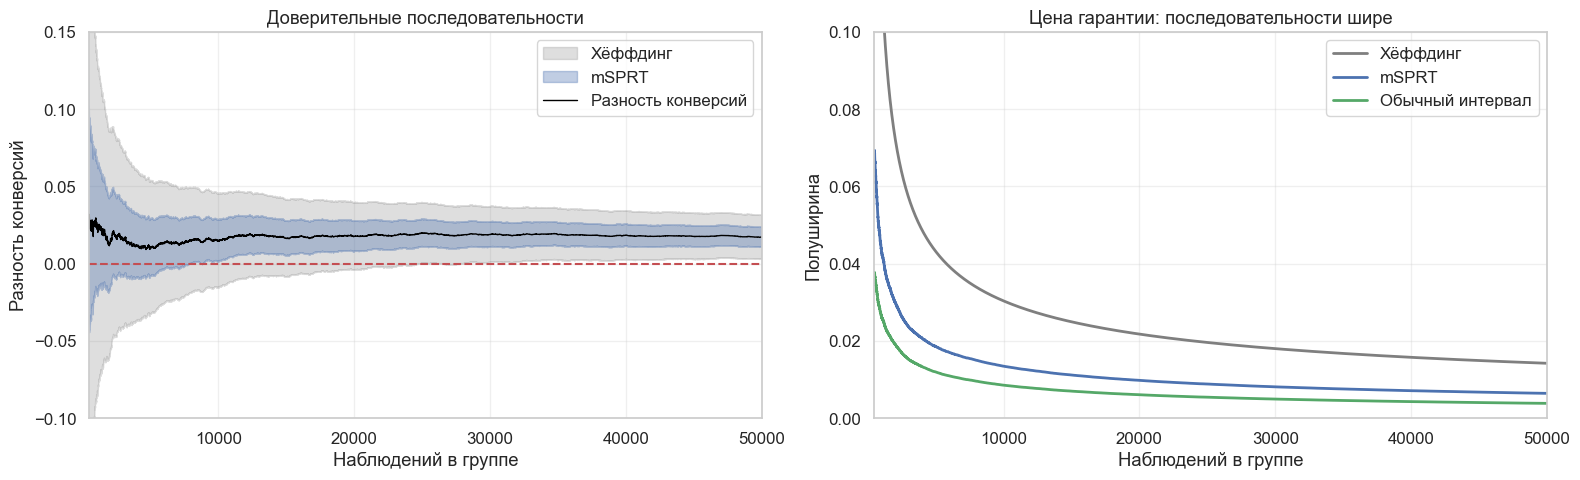

Ноль вышел из интервала: обычный на 18, mSPRT на 7906, Хёффдинг на 24841


,Покрытие на всём пути
Обычный интервал,0.582
mSPRT,0.966
Хёффдинг,1.000


In [8]:
data_a, data_b = generate_ab_data(CONVERSION_A, CONVERSION_B, 50_000, seed=666)
stream = run_msprt(data_a, data_b, tau)
n = stream['n']

radius_fixed = norm.ppf(1 - ALPHA / 2) * np.sqrt(2 * stream['sigma2'] / n)
radius_msprt = msprt_radius(n, stream['sigma2'], tau)
radius_hoeffding = hoeffding_radius(n)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].fill_between(n, stream['difference'] - radius_hoeffding, stream['difference'] + radius_hoeffding, color=GRAY, alpha=0.25, label='Хёффдинг')
axes[0].fill_between(n, stream['difference'] - radius_msprt, stream['difference'] + radius_msprt, color=BLUE, alpha=0.35, label='mSPRT')
axes[0].plot(n, stream['difference'], color='black', linewidth=1, label='Разность конверсий')
axes[0].axhline(0, color=RED, linestyle='--', linewidth=1.5)
axes[0].set(xlim=(500, n[-1]), ylim=(-0.1, 0.15), xlabel='Наблюдений в группе', ylabel='Разность конверсий', title='Доверительные последовательности')
axes[0].legend()

axes[1].plot(n, radius_hoeffding, color=GRAY, linewidth=2, label='Хёффдинг')
axes[1].plot(n, radius_msprt, color=BLUE, linewidth=2, label='mSPRT')
axes[1].plot(n, radius_fixed, color=GREEN, linewidth=2, label='Обычный интервал')
axes[1].set(xlim=(500, n[-1]), ylim=(0, 0.1), xlabel='Наблюдений в группе', ylabel='Полуширина', title='Цена гарантии: последовательности шире')
axes[1].legend()
plt.tight_layout()
plt.show()

first_excluded = lambda radius: int(np.argmax(np.abs(stream['difference']) > radius)) + 1
print(f"Ноль вышел из интервала: обычный на {first_excluded(radius_fixed)}, mSPRT на {first_excluded(radius_msprt)}, Хёффдинг на {first_excluded(radius_hoeffding)}")


def coverage_simulation(n_sims: int = 1500, n_max: int = 20_000, p: float = 0.10, seed: int = 5) -> pd.Series:
    """Считает долю A/A-тестов, где интервал ни разу не потерял истинное значение после 500 наблюдений."""
    rng = np.random.default_rng(seed)
    n = np.arange(1, n_max + 1)
    lost = {'Обычный интервал': 0, 'mSPRT': 0, 'Хёффдинг': 0}
    for _ in range(n_sims):
        a = np.cumsum(rng.random(n_max) < p)[499:]
        b = np.cumsum(rng.random(n_max) < p)[499:]
        steps = n[499:]
        difference = np.abs(b - a) / steps
        pooled = (a + b) / (2 * steps)
        sigma2 = np.clip(pooled * (1 - pooled), 1e-6, None)
        lost['Обычный интервал'] += (difference > norm.ppf(1 - ALPHA / 2) * np.sqrt(2 * sigma2 / steps)).any()
        lost['mSPRT'] += (difference > msprt_radius(steps, sigma2, tau)).any()
        lost['Хёффдинг'] += (difference > hoeffding_radius(steps)).any()
    return 1 - pd.Series(lost) / n_sims


coverage = coverage_simulation()
coverage.round(3).to_frame('Покрытие на всём пути')

Обычный интервал не является доверительной последовательностью: за весь A/A-тест он хотя бы раз теряет истинное значение примерно в 42% случаев, поэтому покрытие на всём пути около 58%. Последовательность mSPRT держит 96.6%. Хёффдинг показывает 100%: он рассчитан на самую большую дисперсию, а здесь дисперсия намного меньше.

Цена гарантии видна в примере: ноль выходит из обычного интервала сразу, на 18-м наблюдении, и это случайный выброс. Последовательность mSPRT исключает ноль примерно на 7 900 наблюдений, а хёффдинговская только на 24 800.

## Group Sequential Testing

Group Sequential Testing — адаптация обычной z-статистики к подглядыванию. Статистика остаётся привычной, а меняются границы: они строятся на основе **alpha-spending функции**, которая задаёт, какая часть $\alpha$ потрачена к доле собранных данных $t \in [0, 1]$.

**Откуда берётся идея.** Нормированная статистика после доли данных $t$ ведёт себя как $W(t)/\sqrt{t}$, где $W(t)$ — броуновское движение. Рассмотрим постоянную границу $z_{1-\alpha/2}$ для $W$ и обозначим через $\tau$ момент первого пересечения. Принцип отражения даёт:

$$
\alpha^*(t) = P(\tau \le t) = 2 - 2\Phi\left(\frac{z_{1-\alpha/2}}{\sqrt{t}}\right), \quad t > 0
$$

Это возрастающая функция с $\alpha^*(1) = \alpha$. Пусть мы смотрим только в моменты $t_1 < t_2 < \dots < t_K = 1$. Тогда границы $b_1, \dots, b_K$ для $|Z|$ подбираются так, чтобы ошибка, потраченная на каждом взгляде, равнялась приросту функции:

$$
P\big(|Z(t_1)| < b_1, \dots, |Z(t_{i-1})| < b_{i-1},\ |Z(t_i)| \ge b_i\big) = \alpha^*(t_i) - \alpha^*(t_{i-1})
$$

Граница $b_1$ находится аналитически, а для следующих нужно численное интегрирование или симуляция, потому что $b_i$ зависит от всех предыдущих границ.

Идея GST в том, что вместо $\alpha^*(t)$ можно взять другую возрастающую функцию с $\alpha(0) = 0$ и $\alpha(1) = \alpha$. Важно: **значение функции — это накопленная ошибка, а не порог для текущего взгляда**. Порог $b_i$ всегда получается расчётом.

**Выбор alpha-spending функции**

Здесь $\alpha$ — двусторонний уровень значимости, $t$ — доля пользователей, уже попавших в тест.

| Наименование | Функция $\alpha(t)$ |
| :--- | :--- |
| O'Brien–Fleming (форма Lan–DeMets) | $\alpha(t) = 2 - 2\Phi\left( z_{1-\alpha/2} / \sqrt{t} \right)$ |
| Pocock (форма Lan–DeMets) | $\alpha(t) = \alpha \ln \left(1 + (e - 1) t \right)$ |
| Uniform | $\alpha(t) = \alpha t$ |
| Kim & DeMets, Power family | $\alpha(t) = \alpha t^{x}$ |
| Hwang, Shih & De Cani, Gamma family | $\alpha(t) = \alpha t$ при $\gamma = 0$, иначе $\alpha \frac{1 - e^{-\gamma t}}{1 - e^{-\gamma}}$ |

#### Реализация

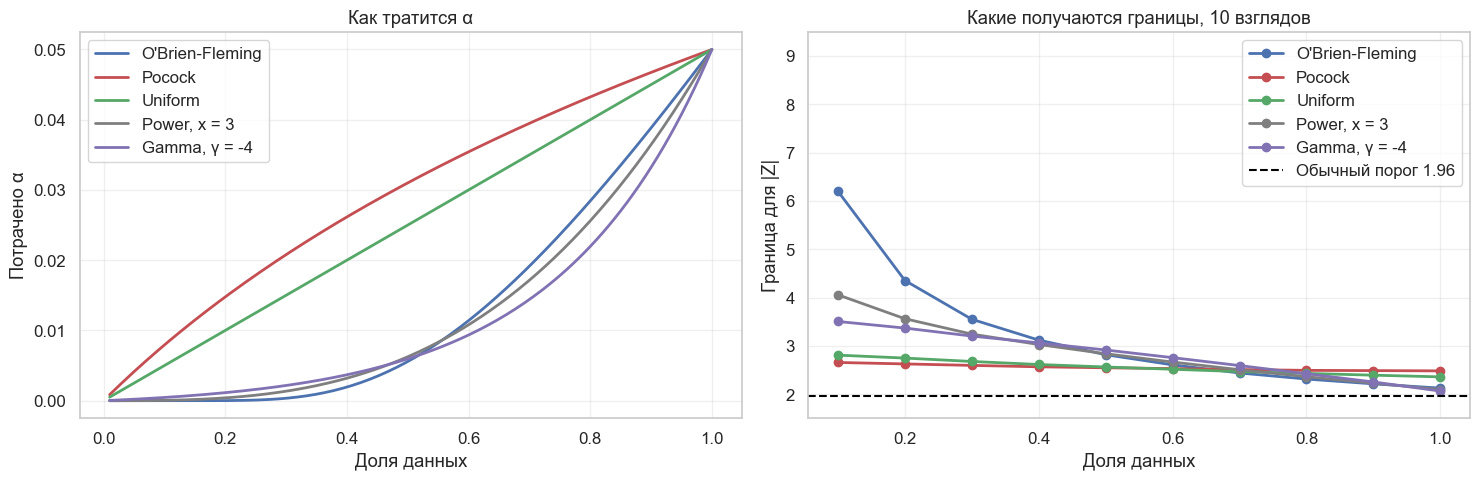

In [9]:
SPENDING = {
    "O'Brien-Fleming": lambda t, a: 2 - 2 * norm.cdf(norm.ppf(1 - a / 2) / np.sqrt(t)),
    'Pocock': lambda t, a: a * np.log(1 + (np.e - 1) * t),
    'Uniform': lambda t, a: a * t,
    'Power, x = 3': lambda t, a: a * t ** 3,
    'Gamma, γ = -4': lambda t, a: a * (1 - np.exp(4 * t)) / (1 - np.exp(4)),
}


def null_paths(looks: np.ndarray, n_paths: int, seed: int = 11) -> np.ndarray:
    """Генерирует нормированные z-статистики в долях данных looks при верной H0."""
    rng = np.random.default_rng(seed)
    increments = np.sqrt(np.diff(looks, prepend=0.0))
    return np.cumsum(rng.standard_normal((n_paths, len(looks)), dtype=np.float32) * increments, axis=1) / np.sqrt(looks)


def gst_boundaries(spending, looks: np.ndarray, alpha: float = ALPHA, n_paths: int = 1_000_000) -> np.ndarray:
    """Подбирает границы для |Z| симуляцией: на каждом взгляде тратится прирост alpha-spending функции."""
    z = np.abs(null_paths(looks, n_paths))
    alive = np.ones(n_paths, dtype=bool)
    spent = np.diff(spending(looks, alpha), prepend=0.0)
    boundaries = []
    for k in range(len(looks)):
        if k == 0:  # первая граница считается точно: до неё нет истории
            boundary = norm.isf(spent[0] / 2)
            boundaries.append(float(boundary))
            alive = z[:, 0] < boundary
            continue
        survivors = z[alive, k]
        target = max(int(round(spent[k] * n_paths)), 1)
        boundary = np.partition(survivors, -target)[-target]
        boundaries.append(float(boundary))
        alive[alive] = survivors < boundary
    return np.array(boundaries)


looks = np.arange(1, 11) / 10
t_grid = np.linspace(0.01, 1, 200)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for (name, spending), color in zip(SPENDING.items(), [BLUE, RED, GREEN, GRAY, '#8172B3']):
    axes[0].plot(t_grid, spending(t_grid, ALPHA), color=color, linewidth=2, label=name)
    axes[1].plot(looks, gst_boundaries(spending, looks), color=color, marker='o', linewidth=2, label=name)
axes[1].axhline(norm.ppf(1 - ALPHA / 2), color='black', linestyle='--', linewidth=1.5, label='Обычный порог 1.96')
axes[0].set(xlabel='Доля данных', ylabel='Потрачено α', title='Как тратится α')
axes[0].legend()
axes[1].set(xlabel='Доля данных', ylabel='Граница для |Z|', ylim=(1.5, 9.5), title='Какие получаются границы, 10 взглядов')
axes[1].legend()
plt.tight_layout()
plt.show()

Функции, тратящие $\alpha$ поздно, дают очень строгие ранние границы и почти обычный порог в конце. Функции, тратящие $\alpha$ рано, позволяют остановиться раньше, но платят более высоким порогом на финальном взгляде.

**Частая ошибка** — подставить накопленное значение $\alpha(t)$ прямо как уровень значимости на текущем взгляде. Проверим, что это даёт, и сравним с корректными границами.

In [10]:
def check_fpr(boundaries: np.ndarray, looks: np.ndarray, n_paths: int = 1_000_000, seed: int = 21) -> float:
    """Считает долю ложных срабатываний на новых путях."""
    return float((np.abs(null_paths(looks, n_paths, seed)) >= boundaries).any(axis=1).mean())


many_looks = np.arange(1, 62) / 61
rows = {}
for name, spending in SPENDING.items():
    wrong = norm.ppf(1 - spending(many_looks, ALPHA) / 2)
    right = gst_boundaries(spending, many_looks)
    rows[name] = {'Подстановка α(t) как порога': check_fpr(wrong, many_looks), 'Рассчитанные границы': check_fpr(right, many_looks)}

pd.DataFrame(rows).T.round(4)

,Подстановка α(t) как порога,Рассчитанные границы
O'Brien-Fleming,0.0846,0.0499
Pocock,0.1666,0.0497
Uniform,0.1443,0.0498
"Power, x = 3",0.0829,0.0500
"Gamma, γ = -4",0.0808,0.0500


Подстановка накопленного $\alpha(t)$ как порога при 61 взгляде даёт 8–17% ложных срабатываний. Рассчитанные границы дают ровно заявленные 5% при любой функции.

**Попробуйте сами.** Эта ячейка интерактивная: запустите её в Colab или Jupyter. Посмотрите, как границы зависят от функции и числа взглядов. Статичная версия показана выше.

In [11]:
def gst_demo(spending: str = "O'Brien-Fleming", looks_count: int = 10) -> None:
    """Показывает границы GST и проверяет долю ложных срабатываний."""
    grid = np.arange(1, looks_count + 1) / looks_count
    boundaries = gst_boundaries(SPENDING[spending], grid, n_paths=300_000)

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.step(grid, boundaries, where='mid', color=BLUE, linewidth=2)
    ax.scatter(grid, boundaries, color=BLUE, zorder=3)
    ax.axhline(norm.ppf(1 - ALPHA / 2), color=GRAY, linestyle='--', linewidth=1.5)
    ax.set(xlabel='Доля данных', ylabel='Граница для |Z|', ylim=(1.5, 9.5),
           title=f'Ложных срабатываний: {check_fpr(boundaries, grid, 300_000):.3f}')
    plt.tight_layout()
    plt.show()


interact(gst_demo, spending=Dropdown(options=list(SPENDING), description='Функция'),
         looks_count=IntSlider(value=10, min=2, max=50, description='Взглядов'));

## Сравнение подходов

Сравним методы в одинаковых условиях. Базовая конверсия 10%, цель — обнаружить рост на 2 процентных пункта с мощностью 80% при $\alpha = 5\%$. Запланированный размер группы рассчитан для обычного теста, а смотрим мы 10 раз равномерно. Все методы останавливаются при значимости, а на последнем взгляде решение принимается окончательно.

Симулируем нормальное приближение для разности средних, поэтому mSPRT здесь использует известную дисперсию. Смотрим на долю значимых тестов и средний размер выборки в процентах от запланированного.

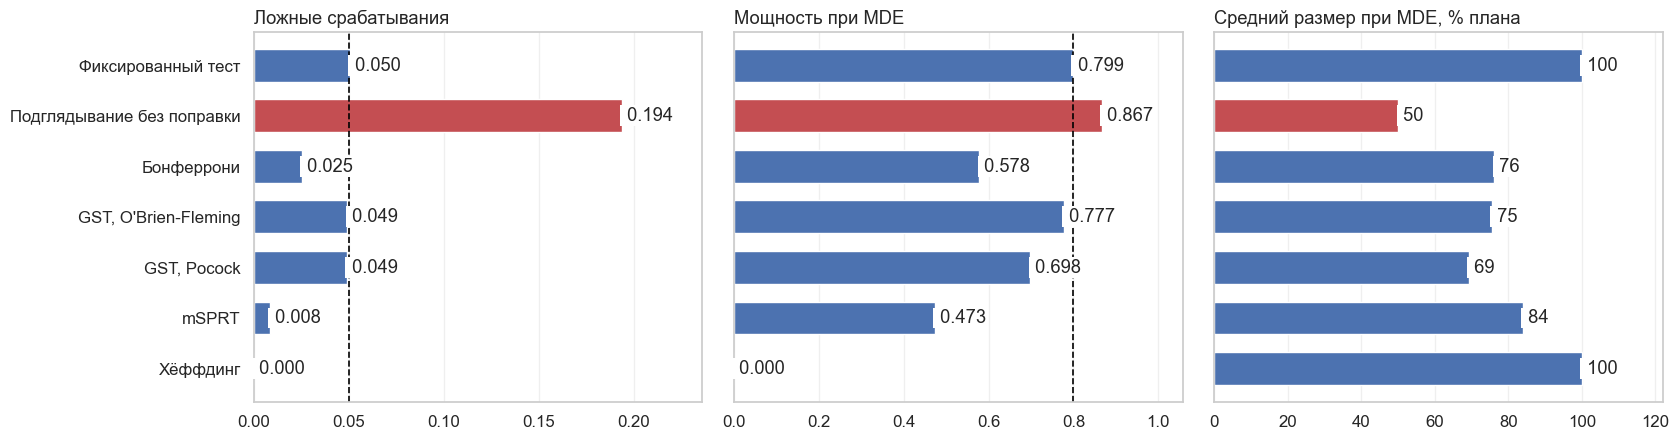

Запланировано наблюдений на группу: 3532


Доля значимых                                \
Сценарий                             A/A Эффект = 1.5 MDE Эффект = MDE   
Метод                                                                    
Фиксированный тест                 0.050            0.987        0.799   
Подглядывание без поправки         0.194            0.993        0.867   
Бонферрони                         0.025            0.938        0.578   
GST, O'Brien-Fleming               0.049            0.984        0.777   
GST, Pocock                        0.049            0.969        0.698   
mSPRT                              0.008            0.901        0.473   
Хёффдинг                           0.000            0.001        0.000   

                           Размер, %                                
Сценарий                         A/A Эффект = 1.5 MDE Эффект = MDE  
Метод                                                               
Фиксированный тест           100.000          100.000      100.000  
Подглядывание без поправки    88.094           30.007       50.126  
Бонферрони                    98.561           49.965       76.228  
GST, O'Brien-Fleming          98.970           54.749       75.487  
GST, Pocock                   97.398           43.983       69.199  
mSPRT                         99.643           59.225       83.948  
Хёффдинг                     100.000           99.995      100.000

In [12]:
p_base, mde = 0.10, 0.02
sigma2_ab = p_base * (1 - p_base)
n_planned = int(np.ceil(2 * sigma2_ab * (norm.ppf(0.975) + norm.ppf(0.8)) ** 2 / mde ** 2))
looks_share = np.arange(1, 11) / 10
looks_n = np.round(looks_share * n_planned)


def z_paths(effect: float, n_sims: int = 300_000, seed: int = 31) -> np.ndarray:
    """Генерирует z-статистики A/B-теста на взглядах looks_n при эффекте effect."""
    rng = np.random.default_rng(seed)
    gaps = np.diff(looks_n, prepend=0.0)
    sums = np.cumsum(rng.normal(effect * gaps, np.sqrt(2 * sigma2_ab * gaps), size=(n_sims, len(looks_n))), axis=1)
    return sums / np.sqrt(2 * sigma2_ab * looks_n)


def evaluate(hits: np.ndarray) -> tuple:
    """Считает долю значимых тестов и средний размер выборки при остановке на первом срабатывании."""
    fired = hits.any(axis=1)
    first = np.where(fired, hits.argmax(axis=1), len(looks_n) - 1)
    return fired.mean(), looks_n[first].mean() / n_planned * 100


def method_hits(z: np.ndarray) -> dict:
    """Возвращает для каждого метода матрицу срабатываний на взглядах."""
    differences = z * np.sqrt(2 * sigma2_ab / looks_n)
    standard_errors = np.sqrt(2 * sigma2_ab / looks_n)
    return {
        'Подглядывание без поправки': np.abs(z) >= norm.ppf(0.975),
        'Бонферрони': np.abs(z) >= norm.ppf(1 - ALPHA / (2 * len(looks_n))),
        "GST, O'Brien-Fleming": np.abs(z) >= gst_boundaries(SPENDING["O'Brien-Fleming"], looks_share),
        'GST, Pocock': np.abs(z) >= gst_boundaries(SPENDING['Pocock'], looks_share),
        'mSPRT': msprt_log_lambda(differences, looks_n, sigma2_ab, mde) >= np.log(1 / ALPHA),
        'Хёффдинг': np.abs(differences) >= hoeffding_radius(looks_n),
        'Фиксированный тест': np.column_stack([np.zeros((len(z), len(looks_n) - 1), dtype=bool), np.abs(z[:, -1]) >= norm.ppf(0.975)]),
    }


records = []
for effect, label in [(0.0, 'A/A'), (mde, 'Эффект = MDE'), (1.5 * mde, 'Эффект = 1.5 MDE')]:
    for name, hits in method_hits(z_paths(effect)).items():
        share, size = evaluate(hits)
        records.append({'Метод': name, 'Сценарий': label, 'Доля значимых': share, 'Размер, %': size})
records = pd.DataFrame(records)

order = ['Фиксированный тест', 'Подглядывание без поправки', 'Бонферрони', "GST, O'Brien-Fleming", 'GST, Pocock', 'mSPRT', 'Хёффдинг']
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
y = np.arange(len(order))[::-1]
panels = [(axes[0], 'A/A', 'Доля значимых', 'Ложные срабатывания'), (axes[1], 'Эффект = MDE', 'Доля значимых', 'Мощность при MDE'), (axes[2], 'Эффект = MDE', 'Размер, %', 'Средний размер при MDE, % плана')]
for ax, scenario, metric, title in panels:
    values = records[records['Сценарий'] == scenario].set_index('Метод').loc[order, metric]
    ax.barh(y, values, color=[RED if name == 'Подглядывание без поправки' else BLUE for name in order], height=0.65)
    for position, value in zip(y, values):
        ax.text(value, position, f' {value:.3f}' if metric != 'Размер, %' else f' {value:.0f}', va='center', zorder=3, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
    ax.set_title(title, loc='left')
    ax.set_xlim(0, values.max() * 1.22)
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(y, order)
axes[0].axvline(ALPHA, color='black', linestyle='--', linewidth=1.2)
axes[1].axvline(0.8, color='black', linestyle='--', linewidth=1.2)
plt.tight_layout()
plt.show()

print(f'Запланировано наблюдений на группу: {n_planned}')
records.pivot(index='Метод', columns='Сценарий', values=['Доля значимых', 'Размер, %']).loc[order].round(3)

Что показывает сравнение:

* **Подглядывание без поправки** выглядит лучше всех по мощности и размеру выборки, но это иллюзия: ложных срабатываний 19%.
* **Бонферрони** честен, но теряет мощность: 58% вместо 80%, а ошибка 2.5% вместо 5% показывает, что поправка слишком строгая для зависимых взглядов.
* **GST с O'Brien–Fleming** почти не теряет в мощности (78%) и экономит в среднем 25% выборки при MDE и 45% при эффекте в 1.5 MDE.
* **GST с Pocock** останавливается раньше (69% плана), но платит мощностью (70%): потраченная рано $\alpha$ повышает финальный порог.
* **mSPRT** при 10 взглядах сильно консервативен: 0.8% ложных срабатываний и 47% мощности. Гарантия рассчитана на просмотр в любой момент, а мы смотрим редко. Зато он не требует заранее знать размер выборки.
* **Хёффдинг** на такой выборке вообще не срабатывает: его граница рассчитана на максимальную дисперсию, а у разности конверсий около 10% она в несколько раз меньше. Гарантия строгая, но для редких событий метод почти бесполезен.

**Always Valid Inference**

* Плюсы
  1. Простота реализации.
  2. Не требует заранее знать размер выборки и допускает неограниченную выборку.
  3. Допускает произвольные правила остановки.
  4. Работает и с потоковыми, и с пакетными данными.
* Минусы
  1. Нужно выбрать параметр смешивающего распределения.
  2. Сложнее объяснить тем, кто учился на традиционной проверке гипотез.
  3. При пакетном анализе мощность ниже, чем у потокового режима: гарантия рассчитана на просмотр в любой момент, а мы смотрим редко.

**Group Sequential Testing**

* Плюсы
  1. Не нужно заранее решать, сколько взглядов сделать и когда. Если не смотреть на данные до конца, тест в точности совпадает с обычным z-тестом.
  2. $\alpha$ тратится только во время взгляда: пропущенный взгляд сохраняет неиспользованную $\alpha$ на потом.
  3. Легко объяснить благодаря связи с z-тестом.
* Минусы
  1. Нужно заранее знать или оценить максимальный размер выборки. Если выйти за него, гарантия нарушается.
  2. Нужно выбрать alpha-spending функцию. Если план выдержан, выбор не критичен, но при неточной оценке выборки он влияет на мощность.
  3. Критические значения получаются численно. Задача усложняется с ростом числа взглядов, поэтому GST неудобен в потоковом режиме.

**Какой метод выбрать** (рекомендации Spotify):

| Ситуация | Что использовать |
| :--- | :--- |
| Размер выборки можно хорошо оценить, данные приходят пакетами, выходить за план не нужно | GST |
| Размер выборки неизвестен, тест может идти долго, нужно быстро ловить сильные ухудшения в потоке | Always Valid Inference, mSPRT |
| Взглядов мало, и их число зафиксировано заранее | Бонферрони |

Важнее выбора конкретного метода сам факт использования хоть какой-то поправки: обычный тест с подглядыванием не контролирует ошибку.

## Заключение

* Подглядывание с обычным порогом кратно завышает долю ложных срабатываний.
* SPRT Вальда экономит наблюдения, но требует простых гипотез и известного базового значения.
* mSPRT снимает эти ограничения смесью альтернатив и использует одну границу $1/\alpha$.
* Always-valid вывод опирается на супермартингалы и неравенство Вилле. Минимум обычных p-значений такой гарантии не даёт.
* В GST значение alpha-spending функции — это накопленная ошибка, а границы рассчитываются численно.
* Для пакетных данных и известного размера выборки обычно лучше GST, для потока и неизвестного размера лучше always-valid методы.